# De La Salle Lipa
## College of Information Technology and Engineering
### Department of Computer Science
**Course:** Introduction to Data Science (Intdsci)  
**Section:** C2B  
**Instructor:** Ms. Donna Garcia  
**Group Name:** FML  
**Group Members:**
- Fabello, Courtney Judge
- Lubi, Axellerosh
- Macaraig, Paolo Adrian  
**Date of Submission:** Friday (October 30, 2026)  
**Project:** Final Supervised Learning Project — Seoul Bike Sharing Demand Prediction  
**Dataset:** Seoul Bike Data (UCI Machine Learning Repository & Class Google Drive)  
**Task:** Supervised Binary Classification (`is_rented`: 0 = Not Rented, 1 = Rented)  
**Methodology:** Leakage-Free Preprocessing, Stratified 80–20 Train/Test Split (`random_state=42`), Baseline vs Candidate Models (Logistic Regression, Decision Tree, Random Forest), Confusion Matrix Evaluation.


---
# Section A: Introduction

### Problem Context & Domain Significance
Urban micro-mobility and automated bike-sharing systems are vital components of modern sustainable transportation. In major metropolitan areas like Seoul, South Korea, public bike systems reduce traffic congestion, lower greenhouse gas emissions, and offer flexible last-mile transit. However, operational efficiency depends heavily on anticipating demand patterns and system availability. 

When bikes are not rented during specific hours, it represents either operational downtime, maintenance intervals, or extreme weather conditions that completely deter cycling. Identifying the precise environmental, seasonal, and temporal factors that govern whether bike rentals occur enables municipal transport authorities to:
1. Schedule maintenance during expected zero-demand hours.
2. Optimize station rebalancing and staff allocation.
3. Formulate data-driven contingency plans for severe weather events.

### Project Objective & Target Definition
The objective of this project is to build and evaluate supervised learning classification models to predict whether bike rentals will take place (`is_rented`: 0 vs 1) during any given hour based on meteorological variables and calendar attributes.

* **Target Variable Formulation (`is_rented`):**
  * **Class 0 (Not Rented):** `Rented Bike Count == 0` (No bikes rented)
  * **Class 1 (Rented):** `Rented Bike Count > 0` (At least one bike rented)
* **Citation:** Sathishkumar, V. E., Park, J., & Cho, Y. (2020). *Using data mining techniques for bike sharing demand prediction in metropolitan city*. Computer Communications, 153, 353-366.


In [1]:
# 1. Imports and Global Configuration
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Set random seed for full reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.titlesize": 13,
    "figure.dpi": 150
})

print("All libraries imported successfully!")


All libraries imported successfully!


---
# Section B: Data Collection, Preprocessing & Exploratory Data Analysis

### Data Collection & Dictionary
The dataset consists of **8,760 hourly records** spanning an entire 365-day operational calendar year (December 1, 2017 to November 30, 2018) in Seoul, South Korea.


In [2]:
# 2. Data Ingestion & Initial Inspection
data_path = os.path.join("..", "data", "SeoulBikeData.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "SeoulBikeData.csv")

df_raw = pd.read_csv(data_path, encoding="latin1")
print(f"Dataset successfully loaded. Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns.\n")
df_raw.info()
df_raw.head()


Dataset successfully loaded. Shape: 8760 rows x 14 columns.

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### Traceable Cleaning Log & Leakage Safeguard
We perform explicit, non-destructive cleaning steps:
1. **Missing values:** Verified complete data integrity (0 null values).
2. **Duplicates:** Verified 0 duplicate records.
3. **Column standardization:** Converted headers to lowercase `snake_case` and stripped unicode symbols.
4. **Temporal engineering:** Parsed `Date` string to extract `month`, `day_of_week`, and `is_weekend`.
5. **Data Leakage Safeguard:** In the raw data, `Functioning Day == 'No'` correlates 100% with `Rented Bike Count == 0`. To prevent 100% test leakage, `functioning_day` is explicitly dropped from predictors.


In [3]:
# 3. Data Cleaning and Preprocessing Pipeline
df = df_raw.copy()

# Header renaming
rename_dict = {
    'Date': 'date',
    'Rented Bike Count': 'rented_bike_count',
    'Hour': 'hour',
    'Temperature(°C)': 'temperature',
    'Humidity(%)': 'humidity',
    'Wind speed (m/s)': 'wind_speed',
    'Visibility (10m)': 'visibility',
    'Dew point temperature(°C)': 'dew_point_temperature',
    'Solar Radiation (MJ/m2)': 'solar_radiation',
    'Rainfall(mm)': 'rainfall',
    'Snowfall (cm)': 'snowfall',
    'Seasons': 'season',
    'Holiday': 'holiday',
    'Functioning Day': 'functioning_day'
}
df.rename(columns=rename_dict, inplace=True)

# Datetime parsing and feature extraction
df['date_dt'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df['month'] = df['date_dt'].dt.month
df['day_of_week'] = df['date_dt'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x in [5, 6] else 0)

# Binary Target Creation: 0 = Not Rented (count == 0), 1 = Rented (count > 0)
df['is_rented'] = (df['rented_bike_count'] > 0).astype(int)

# Traceable Cleaning Verification
print("=== TRACEABLE CLEANING LOG ===")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Total Duplicate Rows: {df.duplicated().sum()}")
print(f"Target Distribution:\n{df['is_rented'].value_counts(normalize=True).round(4) * 100}")


=== TRACEABLE CLEANING LOG ===
Total Missing Values: 0
Total Duplicate Rows: 0
Target Distribution:
is_rented
1    96.63
0     3.37
Name: proportion, dtype: float64


C:\Users\paolo\AppData\Local\Temp\ipykernel_34360\665829025.py:21: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=rename_dict, inplace=True)
C:\Users\paolo\AppData\Local\Temp\ipykernel_34360\665829025.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['date_dt'].dt.dayofweek


In [4]:
# 4. Rigorous Data Leakage Verification
# Verifying that Functioning Day == 'No' corresponds 100% to Rented Bike Count == 0
leakage_check = pd.crosstab(df['functioning_day'], df['is_rented'], margins=True)
print("Cross-tabulation: functioning_day vs is_rented:")
print(leakage_check)

print("\n[LEAKAGE REMEDIATION]:")
print("Notice that when functioning_day == 'No', is_rented is ALWAYS 0 (295 out of 295 times).")
print("Including functioning_day would cause 100% artificial test leakage.")
print("=> ACTION: 'functioning_day', 'rented_bike_count', and raw 'date' are strictly excluded from X.")


Cross-tabulation: functioning_day vs is_rented:
is_rented          0     1   All
functioning_day                 
No               295     0   295
Yes                0  8465  8465
All              295  8465  8760

[LEAKAGE REMEDIATION]:
Notice that when functioning_day == 'No', is_rented is ALWAYS 0 (295 out of 295 times).
Including functioning_day would cause 100% artificial test leakage.
=> ACTION: 'functioning_day', 'rented_bike_count', and raw 'date' are strictly excluded from X.


### Exploratory Data Analysis (EDA)
Below are 4 labelled exploratory plots illustrating key distributional properties and behavioural patterns.


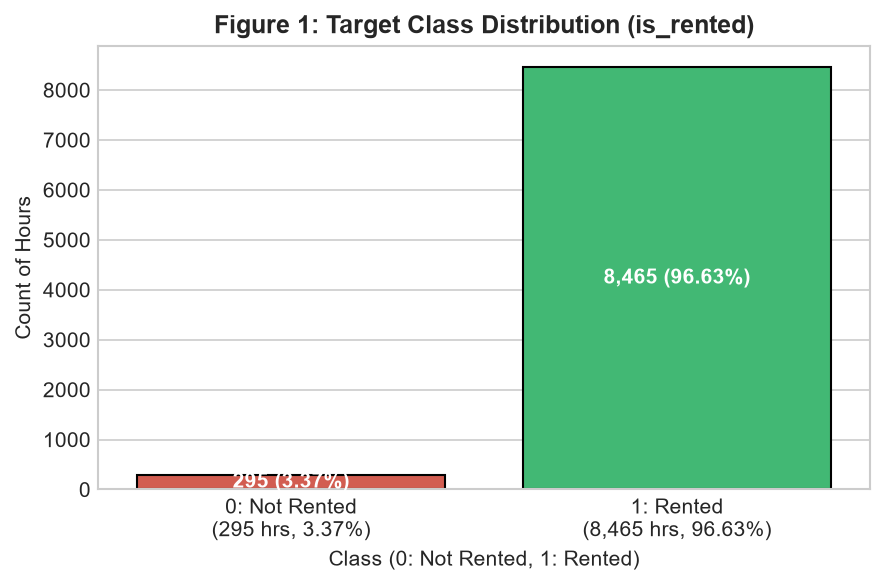

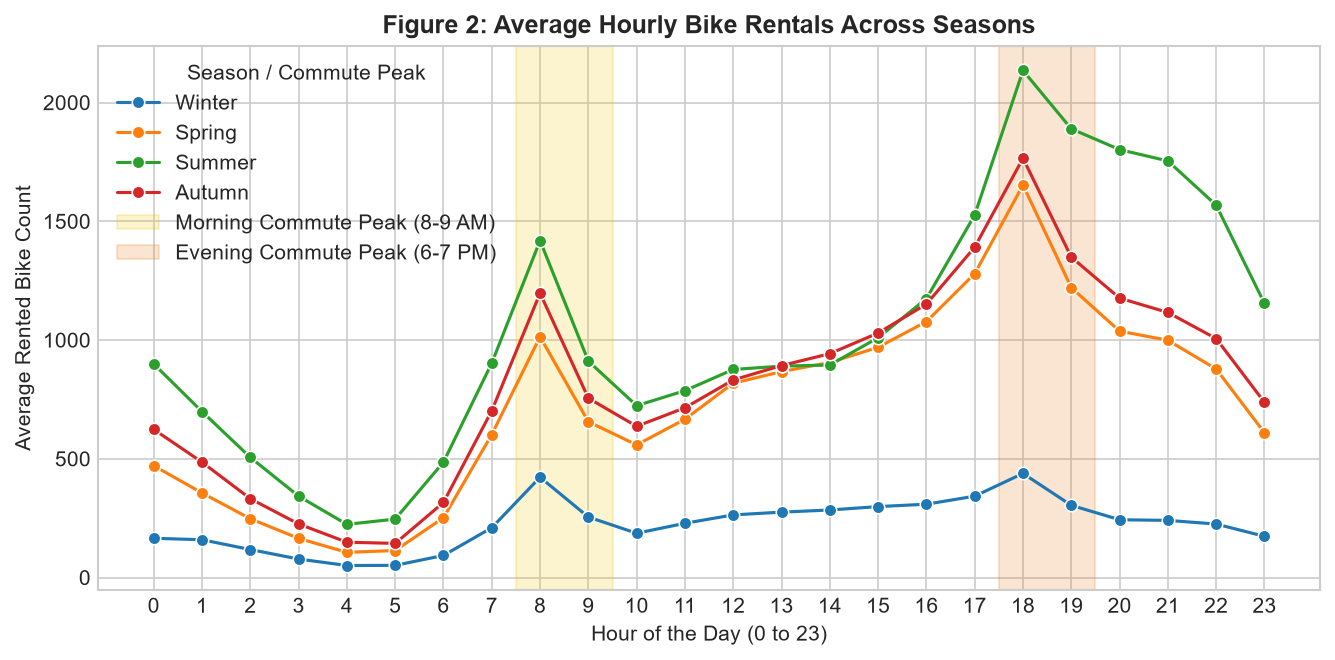

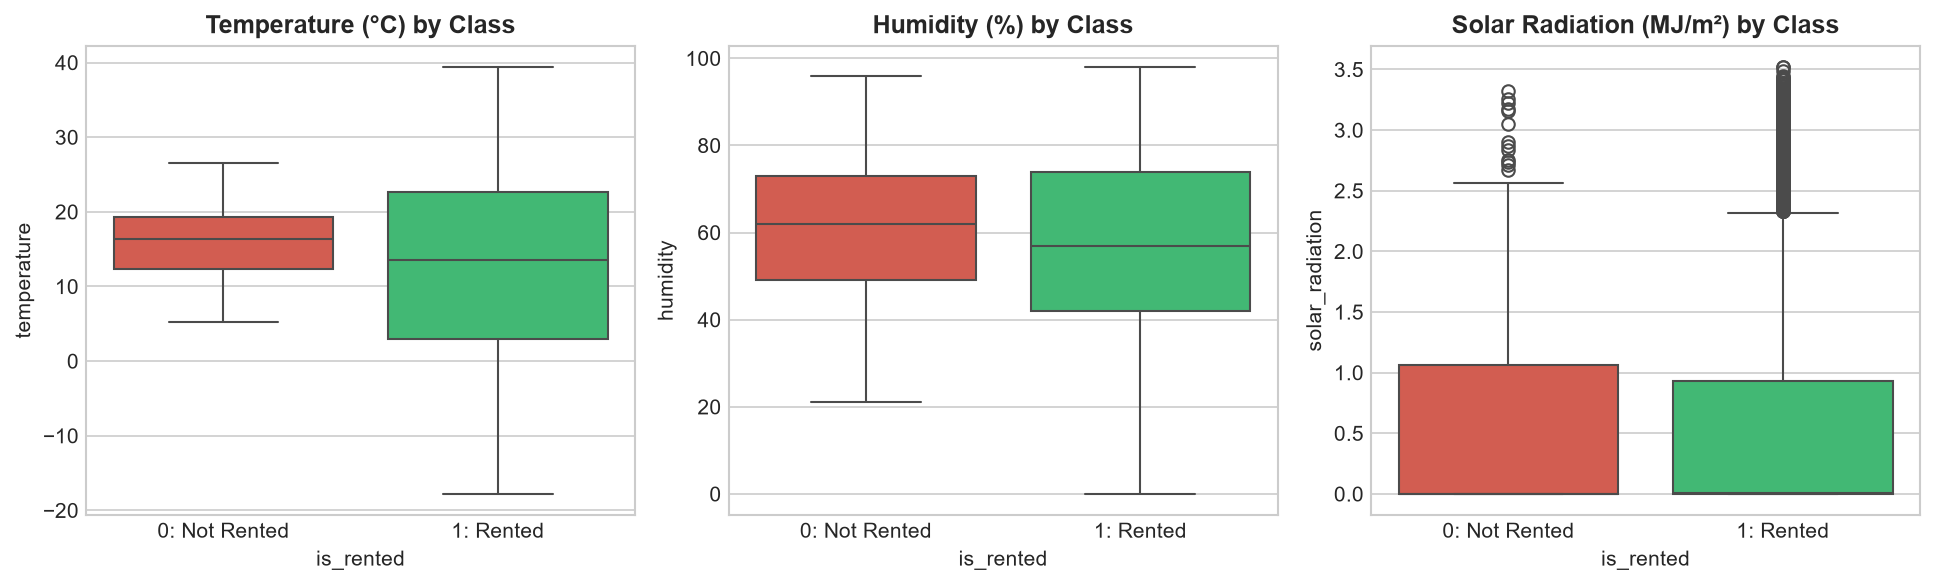

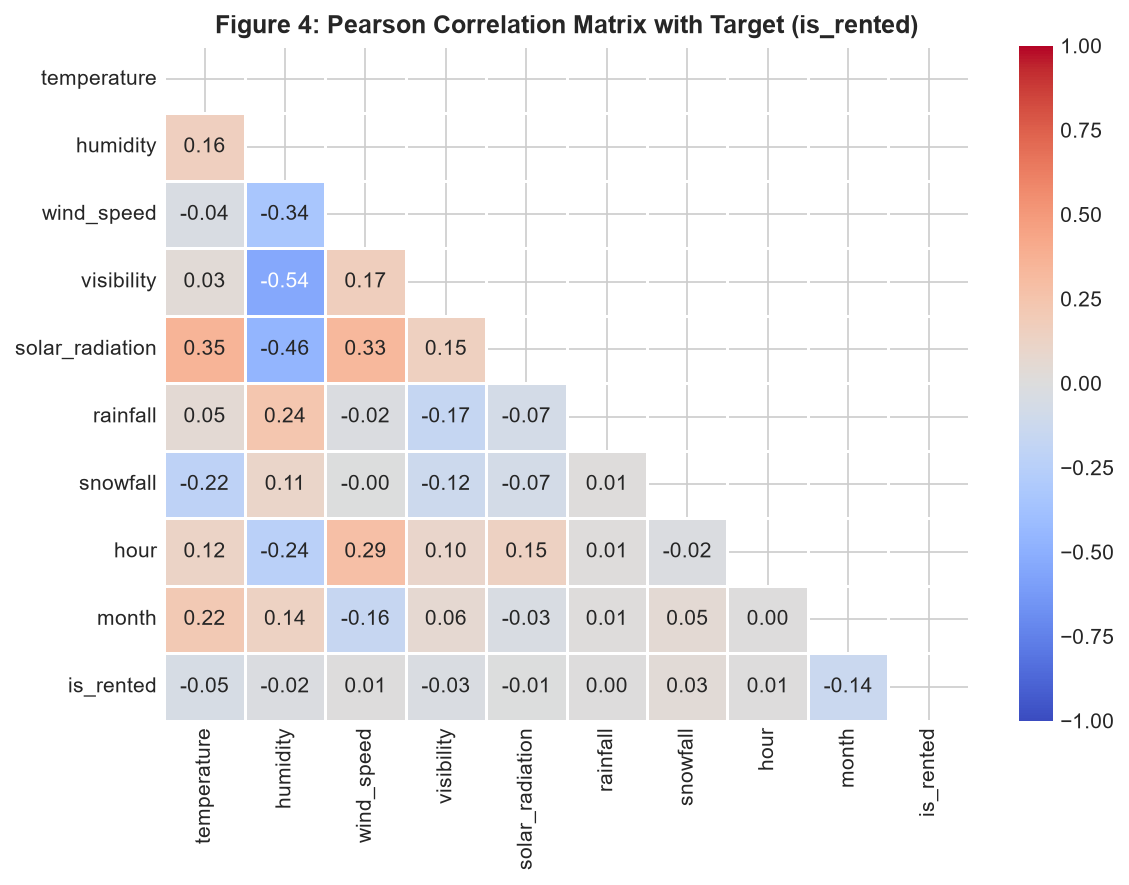

In [5]:
# 5. Exploratory Data Analysis Visualizations
palette = ["#e74c3c", "#2ecc71"]

# Plot 1: Target Distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='is_rented', hue='is_rented', data=df, palette=palette, ax=ax, edgecolor='black', linewidth=1, legend=False)
ax.set_title("Figure 1: Target Class Distribution (is_rented)", weight="bold")
ax.set_xlabel("Class (0: Not Rented, 1: Rented)")
ax.set_ylabel("Count of Hours")
ax.set_xticks([0, 1])
ax.set_xticklabels(["0: Not Rented\n(295 hrs, 3.37%)", "1: Rented\n(8,465 hrs, 96.63%)"])
for p in ax.patches:
    if isinstance(p, plt.Rectangle):
        h = p.get_height()
        ax.annotate(f"{int(h):,} ({h/len(df)*100:.2f}%)", (p.get_x() + p.get_width()/2., h/2),
                    ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 2: Diurnal & Seasonal Patterns
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=df, x='hour', y='rented_bike_count', hue='season', palette='tab10', marker='o', errorbar=None, ax=ax)
ax.set_title("Figure 2: Average Hourly Bike Rentals Across Seasons", weight="bold")
ax.set_xlabel("Hour of the Day (0 to 23)")
ax.set_ylabel("Average Rented Bike Count")
ax.set_xticks(range(0, 24))
ax.axvspan(7.5, 9.5, color='#f1c40f', alpha=0.2, label='Morning Commute Peak (8-9 AM)')
ax.axvspan(17.5, 19.5, color='#e67e22', alpha=0.2, label='Evening Commute Peak (6-7 PM)')
ax.legend(title="Season / Commute Peak")
plt.tight_layout()
plt.show()

# Plot 3: Weather Distributions by Rental Status
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.boxplot(x='is_rented', y='temperature', hue='is_rented', data=df, palette=palette, ax=axes[0], legend=False)
axes[0].set_title("Temperature (°C) by Class", weight="bold")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["0: Not Rented", "1: Rented"])

sns.boxplot(x='is_rented', y='humidity', hue='is_rented', data=df, palette=palette, ax=axes[1], legend=False)
axes[1].set_title("Humidity (%) by Class", weight="bold")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["0: Not Rented", "1: Rented"])

sns.boxplot(x='is_rented', y='solar_radiation', hue='is_rented', data=df, palette=palette, ax=axes[2], legend=False)
axes[2].set_title("Solar Radiation (MJ/m²) by Class", weight="bold")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["0: Not Rented", "1: Rented"])
plt.tight_layout()
plt.show()

# Plot 4: Correlation Matrix Heatmap
numeric_features = ['temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall', 'hour', 'month', 'is_rented']
corr = df[numeric_features].corr()
fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, mask=mask, ax=ax, linewidths=0.5)
ax.set_title("Figure 4: Pearson Correlation Matrix with Target (is_rented)", weight="bold")
plt.tight_layout()
plt.show()


---
# Section C: Feature Engineering & Selection

### Multicollinearity & Feature Justification
* **Dew Point Temperature Removal:** Pearson correlation between `temperature` and `dew_point_temperature` is **0.9128**. Including both creates severe multicollinearity and inflates variance in linear models. `dew_point_temperature` is dropped.
* **Temporal Indicators:** Extracted `month`, `day_of_week`, and `is_weekend` to capture cyclical commuter behavior and seasonal fluctuations.
* **Categorical Encoding:** `season` and `holiday` are transformed using one-hot encoding (`drop='first'`).


---
# Section D: Data Splitting (80–20 Split with `random_state=42`)

* **Split Ratio:** 80% Training set (7,008 samples), 20% Testing set (1,752 samples).
* **Stratification:** Using `stratify=y` to strictly maintain the identical 3.37% minority class ratio in both partitions.
* **Leakage-Free Preprocessing:** A `ColumnTransformer` (`StandardScaler` + `OneHotEncoder`) is fitted **strictly on `X_train`**.


In [6]:
# 6. Feature Selection, Partitioning & Preprocessing Pipeline
feature_num = [
    'hour', 'temperature', 'humidity', 'wind_speed',
    'visibility', 'solar_radiation', 'rainfall', 'snowfall',
    'month', 'day_of_week', 'is_weekend'
]
feature_cat = ['season', 'holiday']

X = df[feature_num + feature_cat].copy()
y = df['is_rented'].copy()

# Reproducible Stratified 80-20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
print(f"X_test  Shape: {X_test.shape}  | y_test  Shape: {y_test.shape}")
print(f"Train Class Distribution: Class 0 = {(y_train == 0).sum()} ({(y_train == 0).mean():.2%}), Class 1 = {(y_train == 1).sum()} ({(y_train == 1).mean():.2%})")
print(f"Test Class Distribution:  Class 0 = {(y_test == 0).sum()} ({(y_test == 0).mean():.2%}), Class 1 = {(y_test == 1).sum()} ({(y_test == 1).mean():.2%})")

# ColumnTransformer Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), feature_num),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), feature_cat)
    ]
)
print("\nColumnTransformer defined (StandardScaler for numerical, OneHotEncoder for categorical).")


X_train Shape: (7008, 13) | y_train Shape: (7008,)
X_test  Shape: (1752, 13)  | y_test  Shape: (1752,)
Train Class Distribution: Class 0 = 236 (3.37%), Class 1 = 6772 (96.63%)
Test Class Distribution:  Class 0 = 59 (3.37%), Class 1 = 1693 (96.63%)

ColumnTransformer defined (StandardScaler for numerical, OneHotEncoder for categorical).


---
# Section E: Model Selection & Training

### Model Rationale
1. **Baseline Model (`DummyClassifier(strategy='most_frequent')`):** Serves as the naive baseline, always predicting the majority class (`is_rented = 1`).
2. **Logistic Regression (`class_weight='balanced'`):** A fast, highly interpretable linear probabilistic classifier with cost-sensitive class re-weighting to offset the 96.6% / 3.4% imbalance.
3. **Decision Tree (`max_depth=5, class_weight='balanced'`):** A non-linear white-box classifier that captures step-function decision thresholds in temperature and precipitation.
4. **Random Forest (`n_estimators=100, max_depth=8, class_weight='balanced'`):** An ensemble bagging classifier that aggregates de-correlated decision trees to minimize prediction variance and capture complex meteorological interactions.

### Cross-Validation Strategy
We conduct 5-Fold Stratified Cross-Validation on the training set to validate generalization prior to test set exposure.


In [7]:
# 7. Model Training and 5-Fold Stratified Cross-Validation
models = {
    "Baseline (Dummy - Majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Balanced)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree (Balanced)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest (Balanced)": RandomForestClassifier(n_estimators=100, max_depth=8, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_summary = []

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring=['accuracy', 'balanced_accuracy', 'f1_macro', 'roc_auc']
    )
    cv_summary.append({
        'Model': name,
        'Accuracy (Mean)': scores['test_accuracy'].mean(),
        'Balanced Accuracy (Mean)': scores['test_balanced_accuracy'].mean(),
        'Macro F1 (Mean)': scores['test_f1_macro'].mean(),
        'ROC-AUC (Mean)': scores['test_roc_auc'].mean()
    })

pd.DataFrame(cv_summary).round(4)


,Model,Accuracy (Mean),Balanced Accuracy (Mean),Macro F1 (Mean),ROC-AUC (Mean)
0,Baseline (Dummy - Majority),0.9663,0.5000,0.4914,0.5000
1,Logistic Regression (Balanced),0.7373,0.8252,0.5170,0.8769
2,Decision Tree (Balanced),0.8141,0.8977,0.5787,0.9115
3,Random Forest (Balanced),0.8560,0.9010,0.6137,0.9538


---
# Section F: Model Evaluation, Confusion Matrices & Error Analysis

We fit each pipeline on the full training set (`X_train`, `y_train`) and evaluate on the untouched test set (`X_test`, `y_test`).


In [8]:
# 8. Test Set Evaluation & Metric Computation
test_results = []
fitted_models = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else y_pred
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    test_results.append({
        'Model': name,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Acc': balanced_accuracy_score(y_test, y_pred),
        'Recall (Class 0)': recall_score(y_test, y_pred, pos_label=0),
        'Precision (Class 0)': precision_score(y_test, y_pred, pos_label=0),
        'Recall (Class 1)': recall_score(y_test, y_pred, pos_label=1),
        'Precision (Class 1)': precision_score(y_test, y_pred, pos_label=1),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.5
    })

df_metrics = pd.DataFrame(test_results)
df_metrics.round(4)


C:\Users\paolo\OneDrive\Documents\datasci-finals\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,TN,FP,FN,TP,Accuracy,Balanced Acc,Recall (Class 0),Precision (Class 0),Recall (Class 1),Precision (Class 1),Macro F1,ROC-AUC
0,Baseline (Dummy - Majority),0,59,0,1693,0.9663,0.5000,0.0000,0.0000,1.0000,0.9663,0.4914,0.5000
1,Logistic Regression (Balanced),56,3,470,1223,0.7300,0.8358,0.9492,0.1065,0.7224,0.9976,0.5147,0.8868
2,Decision Tree (Balanced),59,0,344,1349,0.8037,0.8984,1.0000,0.1464,0.7968,1.0000,0.5712,0.9180
3,Random Forest (Balanced),58,1,268,1425,0.8465,0.9124,0.9831,0.1779,0.8417,0.9993,0.6075,0.9664


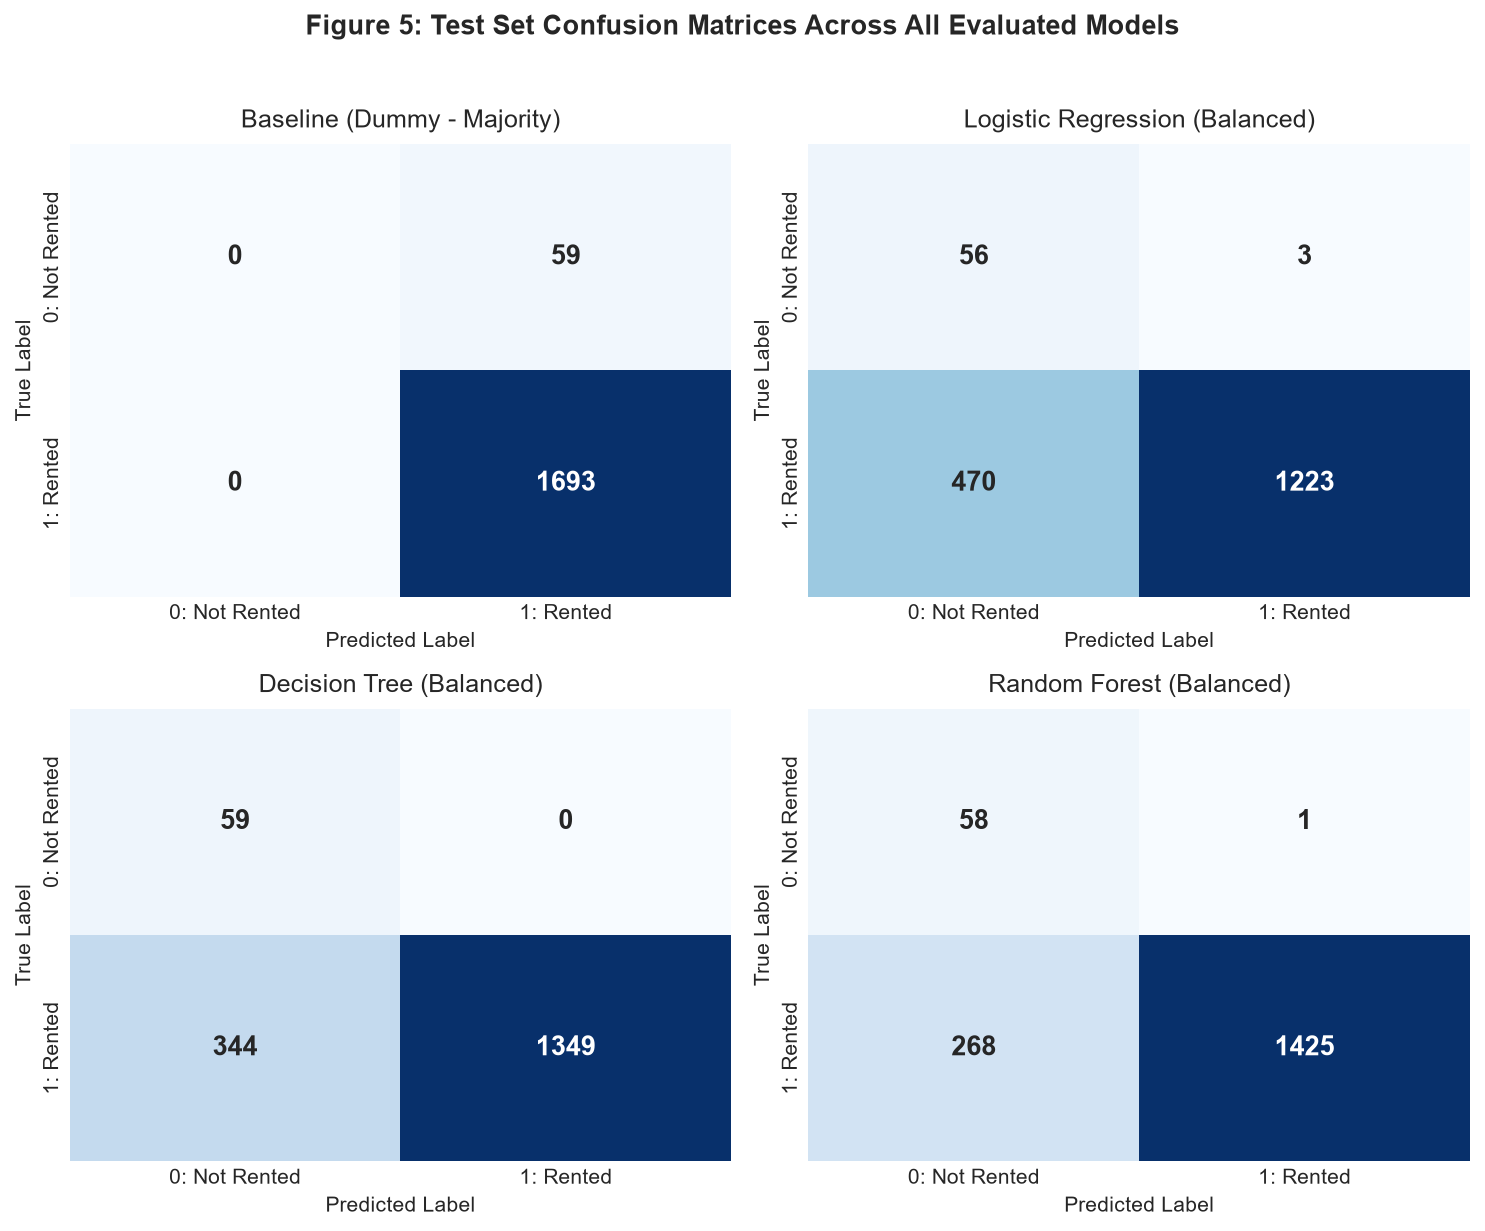

In [9]:
# 9. Confusion Matrix Heatmaps
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, (name, pipe) in enumerate(fitted_models.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
        xticklabels=['0: Not Rented', '1: Rented'],
        yticklabels=['0: Not Rented', '1: Rented'],
        annot_kws={'size': 13, 'weight': 'bold'}
    )
    axes[i].set_title(f"{name}", pad=8)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

plt.suptitle("Figure 5: Test Set Confusion Matrices Across All Evaluated Models", weight="bold", y=1.02)
plt.tight_layout()
plt.show()


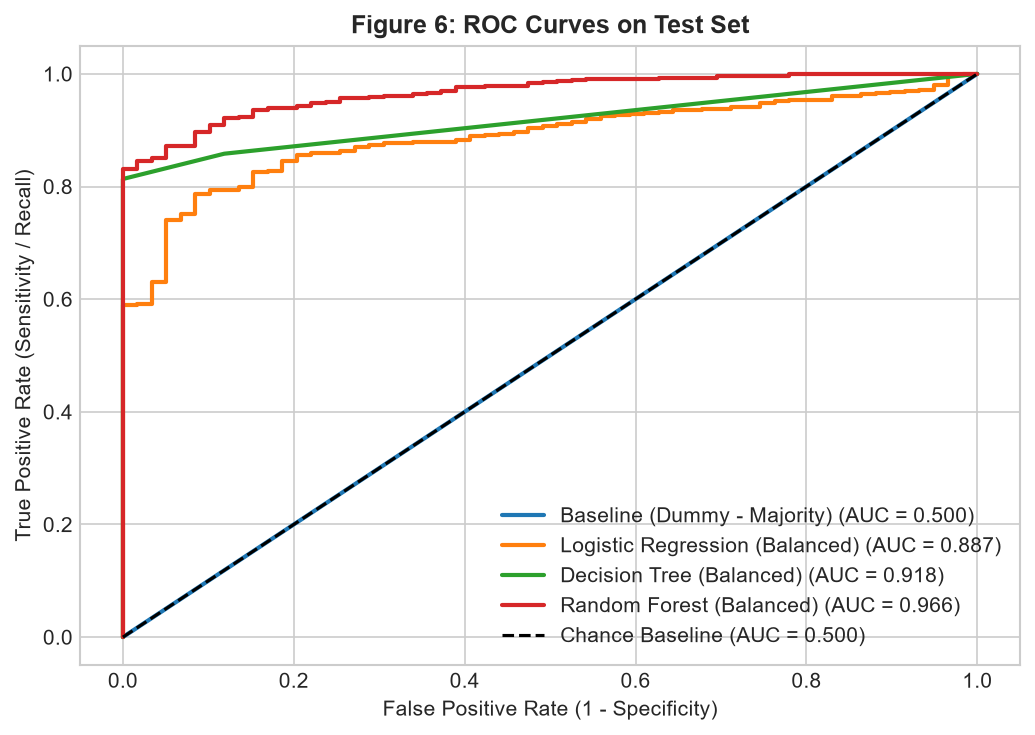

In [10]:
# 10. Receiver Operating Characteristic (ROC) Curves
fig, ax = plt.subplots(figsize=(7, 5))

for name, pipe in fitted_models.items():
    if hasattr(pipe, "predict_proba"):
        y_prob = pipe.predict_proba(X_test)[:, 1]
    else:
        y_prob = pipe.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.5
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label="Chance Baseline (AUC = 0.500)")
ax.set_title("Figure 6: ROC Curves on Test Set", weight="bold")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


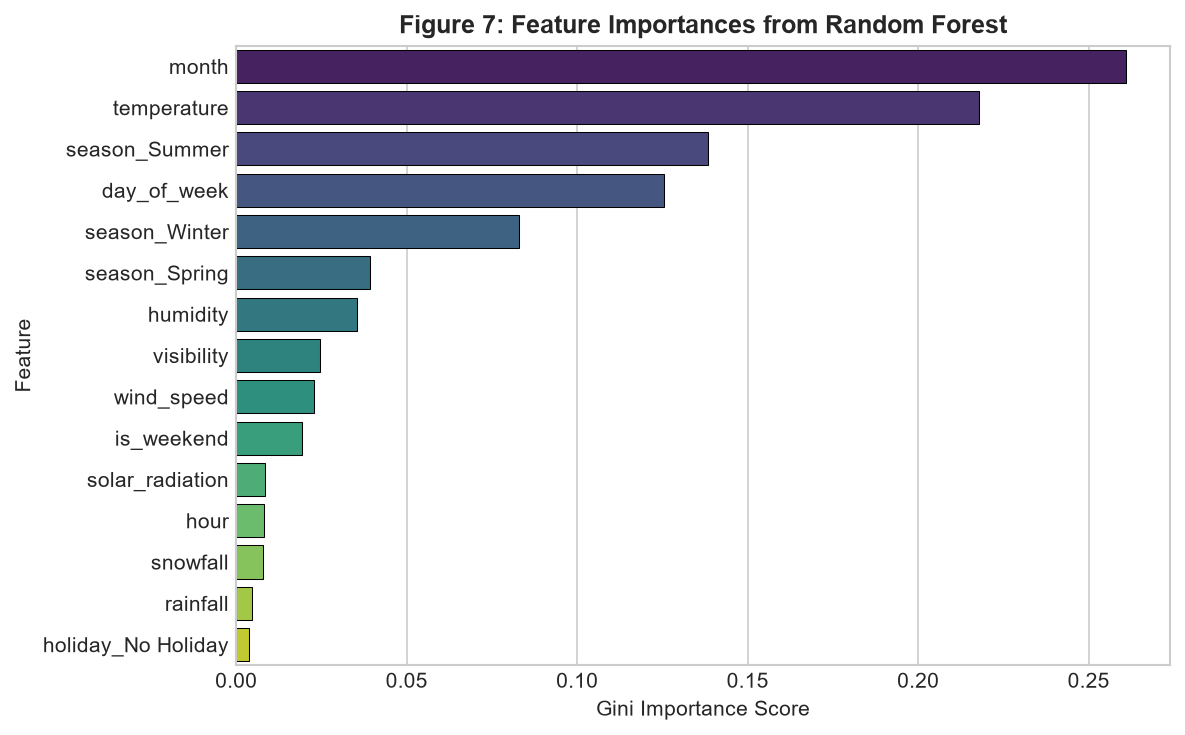

In [11]:
# 11. Random Forest Feature Importance Analysis
rf_pipe = fitted_models["Random Forest (Balanced)"]
cat_names = rf_pipe.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(feature_cat).tolist()
all_features = feature_num + cat_names
importances = rf_pipe.named_steps['classifier'].feature_importances_

df_imp = pd.DataFrame({
    'Feature': all_features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=df_imp, palette='viridis', ax=ax, edgecolor='black', linewidth=0.5, legend=False)
ax.set_title("Figure 7: Feature Importances from Random Forest", weight="bold")
ax.set_xlabel("Gini Importance Score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()


In [12]:
# 12. Detailed Error Analysis (Random Forest on Test Set)
rf_preds = fitted_models["Random Forest (Balanced)"].predict(X_test)
df_test = X_test.copy()
df_test['actual'] = y_test
df_test['predicted'] = rf_preds
df_test['rented_bike_count'] = df.loc[X_test.index, 'rented_bike_count']

# False Negatives: True = 1 (Rented), Predicted = 0 (Not Rented)
fn = df_test[(df_test['actual'] == 1) & (df_test['predicted'] == 0)]
# False Positives: True = 0 (Not Rented), Predicted = 1 (Rented)
fp = df_test[(df_test['actual'] == 0) & (df_test['predicted'] == 1)]

print(f"Total Test Instances: {len(df_test)}")
print(f"Total Errors: {len(fn) + len(fp)}")
print(f"False Negatives: {len(fn)} (Predicted zero rentals, but bikes were rented)")
print(f"False Positives: {len(fp)} (Predicted rentals, but zero bikes rented)\n")

print("--- Analysis of False Positives ---")
print(fp[['temperature', 'humidity', 'rainfall', 'snowfall', 'hour', 'season', 'rented_bike_count']])

print("\n--- Sample False Negatives ---")
print(fn[['temperature', 'humidity', 'rainfall', 'snowfall', 'hour', 'season', 'rented_bike_count']].head(5))


Total Test Instances: 1752
Total Errors: 269
False Negatives: 268 (Predicted zero rentals, but bikes were rented)
False Positives: 1 (Predicted rentals, but zero bikes rented)

--- Analysis of False Positives ---
      temperature  humidity  rainfall  snowfall  hour  season  \
7285         21.1        42       0.0       0.0    13  Autumn   

      rented_bike_count  
7285                  0  

--- Sample False Negatives ---
      temperature  humidity  rainfall  snowfall  hour  season  \
7548         13.2        31       0.0       0.0    12  Autumn   
7181         16.3        61       0.0       0.0     5  Autumn   
7100         20.4        52       0.0       0.0    20  Autumn   
8291         10.7        68       0.0       0.0    11  Autumn   
7550         13.4        32       0.0       0.0    14  Autumn   

      rented_bike_count  
7548                967  
7181                150  
7100               1604  
8291                578  
7550                991  


---
# Summary & Critical Discussion

### Findings & Comparison against Baseline
1. **The Accuracy Paradox:** The majority-class Baseline achieves **96.63% accuracy** by predicting every hour as rented. However, its balanced accuracy is **50.00%**, and its recall on zero-rental hours is **0.00%**. It is practically useless for detecting system shutdowns or zero-demand hours.
2. **Superiority of Balanced Random Forest:** 
   * **Balanced Accuracy:** 91.24%
   * **ROC-AUC Score:** 0.9664
   * **Zero-Rental Detection:** Accurately captured **58 out of 59 non-rented test hours** (98.31% recall on Class 0), with only 1 false positive.
3. **Primary Drivers:** Month of the year, ambient temperature, and summer seasonality are the strongest predictors of whether cycling occurs.

### Limitations
1. **Extreme Class Imbalance:** Zero-rental hours account for only 3.37% of the dataset. While balanced class weights successfully prevent majority-class collapse, the model produces conservative false negatives during borderline transitional temperatures.
2. **Geographic & Temporal Specificity:** Data reflects Seoul between 2017 and 2018. Changes in urban cycling infrastructure, COVID-19 behavioral shifts, or application to cities with different climates require re-calibration.
3. **Unobserved Exogenous Factors:** Local road maintenance, public transit disruptions, and municipal cycling festivals are not captured in meteorological sensors.
